# G2++ scenarios from BasicG2PP

This notebook runs the BasicG2PP model on `g2pp_input.xlsx` and shows what its scenarios
look like:

1. the inputs,
2. fan charts of short rates and 10-year yields,
3. a check that the deflators reproduce the initial curve,
4. the distribution of the 10-year yield at three horizons,
5. the bond fund that drives the liability model,
6. the summary of the `Validation` space.

The model reads `g2pp_input.xlsx` from the library folder, which holds this notebook;
edit the workbook there and run all cells again to see another input.

Click the badge below to run this notebook online on Google Colab. You need a Google account and need to be logged in to it to run this notebook on Google Colab.
[![Run on Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lifelib-dev/lifelib/blob/current/lifelib/libraries/economic/g2pp-simulation.ipynb)


The next code cell below is relevant only when you run this notebook on Google Colab. It installs lifelib and creates a copy of the library for this notebook.

In [1]:
import sys, os

if 'google.colab' in sys.modules:
    lib = 'economic'; lib_dir = '/content/'+ lib
    if not os.path.exists(lib_dir):
        !pip install lifelib
        import lifelib; lifelib.create(lib, lib_dir)
        
    %cd $lib_dir

In [2]:
import matplotlib.pyplot as plt
import modelx as mx
import numpy as np
import pandas as pd
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from matplotlib.ticker import PercentFormatter

model = mx.read_model("BasicG2PP")
g2pp, validation = model.G2PP, model.Validation
N, n = g2pp.scen_size(), g2pp.step_size()
years = np.arange(n + 1) / 12
print(f"{N:,} stochastic scenarios plus the CE scenario, {n} months ({n / 12:g} years)")

1,000 stochastic scenarios plus the CE scenario, 600 months (50 years)


In [3]:
# Chart style: light-mode tokens of the reference palette, slot 1 (blue) for the
# stochastic scenarios and slot 2 (orange) for the certainty-equivalent (CE) scenario.
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.linewidth": 1, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 1, "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titlelocation": "left", "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "legend.frameon": False,
    "legend.labelcolor": INK_2, "lines.linewidth": 2, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "font.size": 9.5,
})

BANDS = [("1st", 1, "99th", 99), ("5th", 5, "95th", 95), ("25th", 25, "75th", 75)]
WASH = 0.10                              # nested percentile bands, each a 10% wash


def fan(ax, paths, x):
    """Percentile bands and median of the stochastic rows of paths, and the CE row."""
    stochastic = paths[1:]
    for _, lo, _, hi in BANDS:
        ax.fill_between(x, np.percentile(stochastic, lo, axis=0),
                        np.percentile(stochastic, hi, axis=0),
                        color=BLUE, alpha=WASH, linewidth=0)
    ax.plot(x, np.median(stochastic, axis=0), color=BLUE)
    ax.plot(x, paths[0], color=ORANGE)


def fan_legend(target, **kwargs):
    """Legend for fan() on an axes or a figure; nested bands show the opacity they build up to."""
    handles = [Patch(color=BLUE, alpha=1 - (1 - WASH) ** k, linewidth=0,
                     label=f"{lo} to {hi} percentile")
               for k, (lo, _, hi, _) in enumerate(BANDS, start=1)]
    handles += [Line2D([], [], color=BLUE, label="median"),
                Line2D([], [], color=ORANGE, label="CE scenario")]
    target.legend(handles=handles, **kwargs)


def percentile_table(paths, at_years, scale=100, decimals=2):
    """Table view of a fan chart: CE value and percentiles at the given years."""
    idx = [int(round(y * 12)) for y in at_years]
    stochastic = paths[1:, idx]
    table = pd.DataFrame({f"p{q}": np.percentile(stochastic, q, axis=0)
                          for q in (1, 5, 25, 50, 75, 95, 99)},
                         index=pd.Index(at_years, name="year"))
    table.insert(0, "CE", paths[0, idx])
    return (scale * table).round(decimals)

## Inputs

The run settings and G2++ parameters from the `Params` sheet, a few points of the selected
curve, and the selected fund. The example G2++ parameters are illustrative, not calibrated.

In [4]:
display(g2pp.param_table().to_frame("value"))
curve = g2pp.curve_table()[g2pp.curve_id()].dropna()
shown = [m for m in (1, 5, 10, 20, 30, 50, 100, 150) if m in curve.index]
print(f"Curve {g2pp.curve_id()}, {g2pp.compounding()} compounding, spot rates in %:")
display((100 * curve.loc[shown]).round(3).to_frame("spot rate (%)"))
print(f"Fund {g2pp.fund_id()}: {g2pp.fund_cash_share():.0%} cash, and bonds by months to maturity:")
display(g2pp.fund_bond_shares().to_frame("share"))

,value
parameter,
a,0.773
b,0.082
sigma,0.022
eta,0.0104
rho,-0.7
scen_size,1000
step_size,600
seed,1234
antithetic,True


Curve EUR_BASE, annual compounding, spot rates in %:


,spot rate (%)
maturity,
1.0,3.357
5.0,2.323
10.0,2.393
20.0,2.406
30.0,2.534
50.0,2.847
100.0,3.145
150.0,3.247


Fund BOND_MIX: 20% cash, and bonds by months to maturity:


,share
months,
60,0.3
120,0.5


## Short rates and 10-year yields

Each band holds the given share of the stochastic scenarios at each month. The CE scenario
follows the initial forward curve. The input curve has annual maturities and flat forwards
between them, so the CE short rate, and with it the median, steps at whole years. The
median of the short rate sits above the forward by the convexity terms in φ(t).

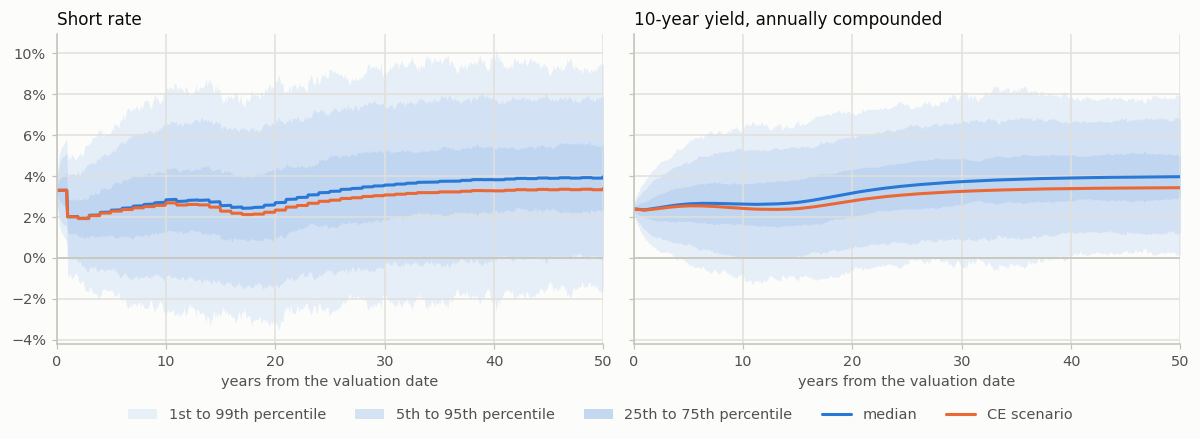

In [5]:
short = g2pp.short_rate_paths()
yield10 = g2pp.spot_rate_paths(120)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, paths, title in [(axes[0], short, "Short rate"),
                         (axes[1], yield10, "10-year yield, annually compounded")]:
    fan(ax, paths, years)
    ax.axhline(0, color=AXIS, linewidth=1)
    ax.set_title(title)
    ax.set_xlabel("years from the valuation date")
    ax.set_xlim(0, years[-1])
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
fan_legend(fig, loc="lower center", ncols=5, bbox_to_anchor=(0.5, 0))
fig.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

In [6]:
at = [y for y in (1, 5, 10, 20, 30, 50, 100, 150) if y * 12 <= n]
print("Short rate (%): the CE value and percentiles of the stochastic scenarios")
display(percentile_table(short, at))
print("10-year yield (%)")
display(percentile_table(yield10, at))

Short rate (%): the CE value and percentiles of the stochastic scenarios


,CE,p1,p5,p25,p50,p75,p95,p99
year,,,,,,,,
1,2.01,-0.69,0.06,1.25,2.01,2.77,3.96,4.71
5,2.28,-1.51,-0.54,1.17,2.33,3.49,5.20,6.17
10,2.69,-2.68,-0.89,1.29,2.84,4.39,6.56,8.35
20,2.34,-3.17,-1.10,1.06,2.70,4.34,6.49,8.56
30,3.08,-2.09,-0.16,1.83,3.56,5.29,7.27,9.20
50,3.40,-1.54,0.12,2.38,3.97,5.56,7.82,9.48


10-year yield (%)


,CE,p1,p5,p25,p50,p75,p95,p99
year,,,,,,,,
1,2.33,1.00,1.38,1.97,2.35,2.72,3.32,3.71
5,2.54,-0.30,0.74,1.80,2.64,3.49,4.58,5.67
10,2.42,-0.93,0.02,1.62,2.63,3.65,5.30,6.31
20,2.79,-0.62,0.48,2.00,3.17,4.35,5.93,7.11
30,3.25,-0.46,0.95,2.55,3.73,4.91,6.58,8.09
50,3.43,0.15,1.23,2.95,3.97,4.99,6.79,7.93


## The deflators reproduce the initial curve

The mean deflator over the stochastic scenarios, divided by the initial discount factor,
should be 1 at every month: E[D(t)] = P^M(0, t). The band is the 95% Monte Carlo
interval, from the standard errors of antithetic pair means in
`Validation.martingale_test()`. It widens with the horizon, because the deflators spread
out as the variance V(0, t) of the integrated short rate grows.

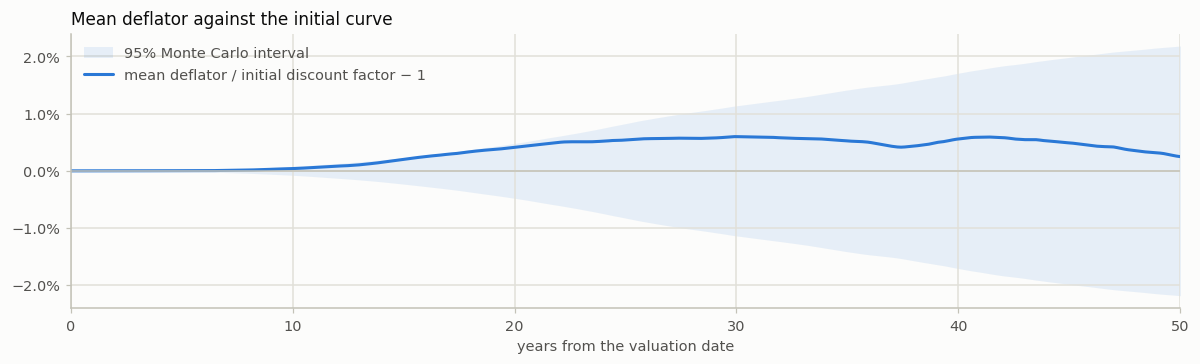

largest |z| over 600 months: 1.79


In [7]:
mart = validation.martingale_test()
ratio = mart["mc"] / mart["theory"] - 1
half_width = 1.96 * mart["se"] / mart["theory"]

fig, ax = plt.subplots(figsize=(11, 3.4))
ax.fill_between(years, -half_width, half_width, color=BLUE, alpha=WASH, linewidth=0,
                label="95% Monte Carlo interval")
ax.plot(years, ratio, color=BLUE, label="mean deflator / initial discount factor − 1")
ax.axhline(0, color=AXIS, linewidth=1)
ax.set_title("Mean deflator against the initial curve")
ax.set_xlabel("years from the valuation date")
ax.set_xlim(0, years[-1])
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
ax.legend(loc="upper left")
fig.tight_layout()
plt.show()
print(f"largest |z| over {len(mart) - 1} months: {mart['z'].abs().max():.2f}")

## Distribution of the 10-year yield

The Gaussian model gives normally distributed yields, so a share of scenarios has
negative rates; each panel prints that share.

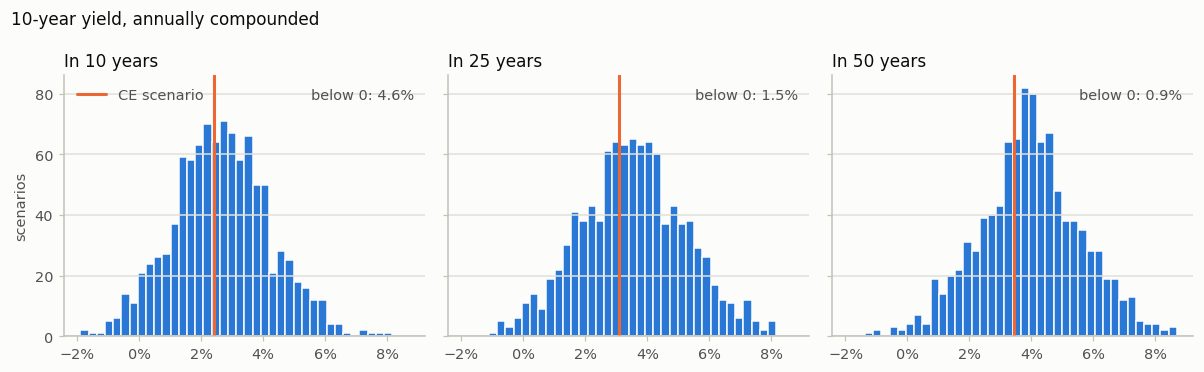

In [8]:
horizons = [y for y in (10, 25, 50) if y * 12 <= n]
values = yield10[1:, [12 * y for y in horizons]]
bins = np.linspace(np.percentile(values, 0.1), np.percentile(values, 99.9), 41)

fig, axes = plt.subplots(1, len(horizons), figsize=(11, 3.4), sharex=True, sharey=True)
for ax, horizon in zip(np.atleast_1d(axes), horizons):
    i = 12 * horizon
    ax.hist(yield10[1:, i], bins=bins, color=BLUE, edgecolor=SURFACE, linewidth=1)
    ax.axvline(yield10[0, i], color=ORANGE, label="CE scenario")
    ax.text(0.97, 0.95, f"below 0: {(yield10[1:, i] < 0).mean():.1%}",
            transform=ax.transAxes, ha="right", va="top", color=INK_2)
    ax.set_title(f"In {horizon} years")
    ax.grid(axis="x", visible=False)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
first = np.atleast_1d(axes)[0]
first.set_ylabel("scenarios")
first.legend(loc="upper left")
fig.suptitle("10-year yield, annually compounded", x=0.01, ha="left", color=INK, fontsize=11)
fig.tight_layout()
plt.show()

## The bond fund

The liability model's fund holds the shares of the `Fund` sheet: zero-coupon bonds by
years to maturity, rebalanced monthly, plus cash. The left panel shows the growth of 1
invested at time 0. Because the fund holds only bonds and the bank account, its deflated
value is a martingale; the right panel checks that its mean stays at 1.

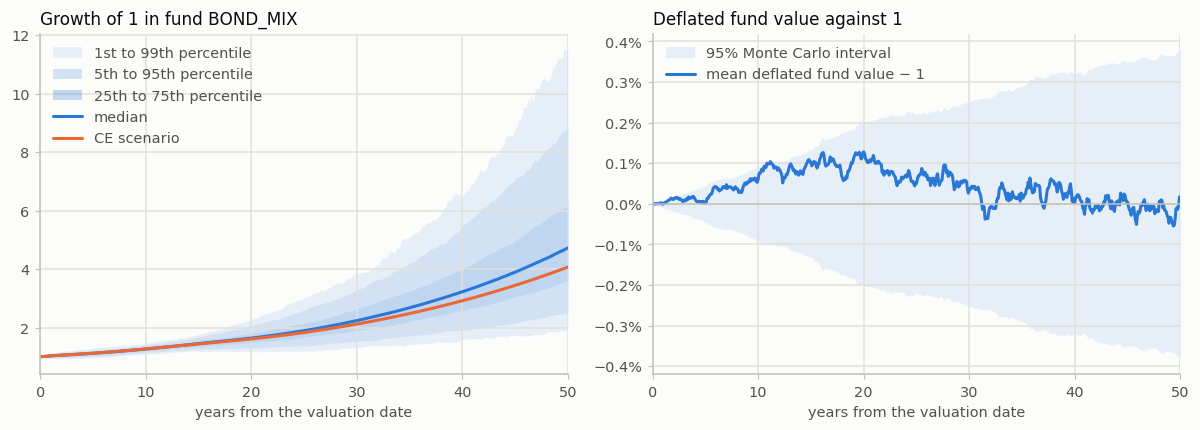

Growth of 1 in fund BOND_MIX: the CE value and percentiles


,CE,p1,p5,p25,p50,p75,p95,p99
year,,,,,,,,
1,1.034,0.952,0.974,1.009,1.033,1.057,1.096,1.121
5,1.122,0.974,1.018,1.075,1.119,1.165,1.231,1.285
10,1.267,1.101,1.144,1.211,1.266,1.322,1.400,1.454
20,1.609,1.179,1.300,1.490,1.640,1.803,2.067,2.278
30,2.119,1.317,1.528,1.897,2.239,2.643,3.279,3.807
50,4.070,1.949,2.507,3.597,4.725,6.196,8.904,11.479


In [9]:
returns = g2pp.fund_return_paths()
growth = np.cumprod(np.hstack([np.ones((N + 1, 1)), 1 + returns]), axis=1)
fund_mart = validation.fund_martingale_test()

fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4))
fan(left, growth, years)
left.set_title(f"Growth of 1 in fund {g2pp.fund_id()}")
left.set_xlabel("years from the valuation date")
left.set_xlim(0, years[-1])
fan_legend(left, loc="upper left")

half_width = 1.96 * fund_mart["se"]
right.fill_between(years, -half_width, half_width, color=BLUE, alpha=WASH, linewidth=0,
                   label="95% Monte Carlo interval")
right.plot(years, fund_mart["mc"] - 1, color=BLUE, label="mean deflated fund value − 1")
right.axhline(0, color=AXIS, linewidth=1)
right.set_title("Deflated fund value against 1")
right.set_xlabel("years from the valuation date")
right.set_xlim(0, years[-1])
right.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=1))
right.legend(loc="upper left")
fig.tight_layout()
plt.show()

print(f"Growth of 1 in fund {g2pp.fund_id()}: the CE value and percentiles")
display(percentile_table(growth, at, scale=1, decimals=3))

## Validation summary

Each test compares Monte Carlo estimates with the values they should converge to, as
z-scores. A test with m z-scores passes if its largest |z| is below the limit
Φ⁻¹(1 − 0.00135/m): the same 0.27% chance of a false alarm as a single 3-sigma check,
so the limit is 3 for one check and about 4.6 for 600 months. A test whose estimate is
exact by construction scores 0. For a new calibration, run this with `scen_size` set to
10,000.

In [10]:
validation.summary()

,checks,max_abs_z,limit,ok,at
martingale_test(),601,1.790468,4.587190,True,198
fund_martingale_test(),601,2.043954,4.587190,True,134
curve_fit_test(),50,1.789351,4.037604,True,17.0
moments_test(),350,2.902763,4.472964,True,"(468, cov xy)"
"zcb_martingale_test(300, 360)",1,0.941041,2.999977,True,"(300, 360)"
"zbp_mc(300, 360, at the money)",1,0.108391,2.999977,True,"(300, 360, 0.8632293178757527)"
"deflator_call_test(300, 0.9)",1,1.359685,2.999977,True,"(300, 0.9)"
